11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 10s 1us/step


C:\Users\M Nawfal\AppData\Roaming\Python\Python314\site-packages\keras\src\layers\reshaping\flatten.py:36: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Training MNIST model...
Epoch 1/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.9286 - loss: 0.2444 - val_accuracy: 0.9629 - val_loss: 0.1189
Epoch 2/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9687 - loss: 0.1032 - val_accuracy: 0.9703 - val_loss: 0.0923
Epoch 3/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9791 - loss: 0.0694 - val_accuracy: 0.9730 - val_loss: 0.0851
Epoch 4/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9840 - loss: 0.0507 - val_accuracy: 0.9722 - val_loss: 0.0931
Epoch 5/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9884 - loss: 0.0378 - val_accuracy: 0.9740 - val_loss: 0.0903
Epoch 6/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9903 - loss: 0.0318 - val_accuracy: 0.9772 - val_loss: 0.0842
Epoch 7/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9908 - loss: 0.0269 - val_accuracy: 0.9744 - val_loss: 0.1034
Epoch 8/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 

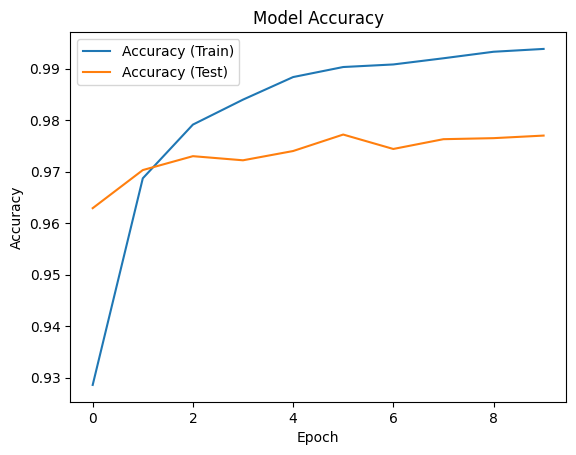

In [1]:
import tensorflow as tf
from tensorflow.keras.datasets import mnist
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Flatten
from tensorflow.keras.utils import to_categorical
import matplotlib.pyplot as plt

# 1. Load dataset MNIST
(X_train, y_train), (X_test, y_test) = mnist.load_data()

# Normalisasi data (0-255 → 0-1)
X_train = X_train / 255.0
X_test = X_test / 255.0

# One-hot encoding label
y_train = to_categorical(y_train, 10)
y_test = to_categorical(y_test, 10)

# 2. Bangun model JST
model = Sequential([
    Flatten(input_shape=(28, 28)),
    Dense(128, activation='relu'),
    Dense(64, activation='relu'),
    Dense(10, activation='softmax')
])

# 3. Kompilasi model
model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

# 4. Latih model
print("Training MNIST model...")
history = model.fit(X_train, y_train, validation_data=(X_test, y_test), epochs=10, batch_size=32, verbose=1)

# 5. Evaluasi model
loss, acc = model.evaluate(X_test, y_test, verbose=0)
print(f"\nAkurasi pada data uji: {acc:.4f}")

# Plot Akurasi
plt.plot(history.history['accuracy'], label='Accuracy (Train)')
plt.plot(history.history['val_accuracy'], label='Accuracy (Test)')
plt.title('Model Accuracy')
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
plt.legend()
plt.show()

## Eksperimen Parameter
- Ubah jumlah neuron di hidden layer (256 dan 128).
- Tambahkan satu hidden layer lagi.
- Bandingkan akurasi.

In [2]:
# Model Eksperimen: 3 Hidden Layer (256, 128, 64)
model_exp = Sequential([
    Flatten(input_shape=(28, 28)),
    Dense(256, activation='relu'),
    Dense(128, activation='relu'),
    Dense(64, activation='relu'),
    Dense(10, activation='softmax')
])

model_exp.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
print("Training Experiment model...")
history_exp = model_exp.fit(X_train, y_train, validation_data=(X_test, y_test), epochs=10, batch_size=32, verbose=0)

loss_exp, acc_exp = model_exp.evaluate(X_test, y_test, verbose=0)
print(f"Akurasi Model Eksperimen: {acc_exp:.4f}")

Training Experiment model...
Akurasi Model Eksperimen: 0.9781
